In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pathlib

RC = {
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 10,
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
}

FIGURE_DIR = pathlib.Path('/users/miccatta/s-ruc/observation_assimilation_transformer/data/figures')

In [2]:
oat_fixed_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-36-57_oat_fixed_B1'
gp_fixed_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-37-27_gp_oat_fixed_B1'
gp_fixed_exact_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-38-50_gp_oat_fixed_B1_exact'
# deep_gp_fixed_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-40-55_deep_gp_oat_fixed_B1'

oat_proportional_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-44-00_oat_proportional_B1'
gp_proportional_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-44-26_gp_oat_proportional_B1'
gp_proportional_exact_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-06_23-45-43_gp_oat_proportional_B1_exact'

In [3]:
def plot_scaling(ax, experiment_path, label, color, step='train', column='mean_s',
                 linestyle='-', marker_face=None, marker='o'):
    
    table = pd.read_csv(pathlib.Path(experiment_path) / 'results.csv')
    step_rows = table[table['step'] == step]
    rows = step_rows[step_rows['status'] == 'ok']
    # ax.plot(rows['n_obs'], rows[column], marker='o', ms=4, lw=1.2, color=color, label=label)
    ax.plot(rows['n_obs'], rows[column], marker=marker, ms=4, lw=1.2, color=color,
            linestyle=linestyle, markerfacecolor=marker_face or color, label=label)

    # Mark the first N_obs that ran out of memory.
    oom_rows = step_rows[step_rows['status'] == 'oom']
    if len(oom_rows) > 0 and len(rows) > 0:
        n_last = rows['n_obs'].iloc[-1]
        y_last = rows[column].iloc[-1]
        n_oom = oom_rows['n_obs'].iloc[0]
        # Dotted line from the last measured point to the OOM size, at the same height.
        ax.plot([n_last, n_oom], [y_last, y_last], ls=':', lw=1.2, color=color)
        ax.plot(n_oom, y_last, marker='x', ms=6, mew=1.5, ls='none', color=color)
        ax.annotate('OOM', (n_oom, y_last), xytext=(4, 4), textcoords='offset points',
                    fontsize=8.5, color='0.3')

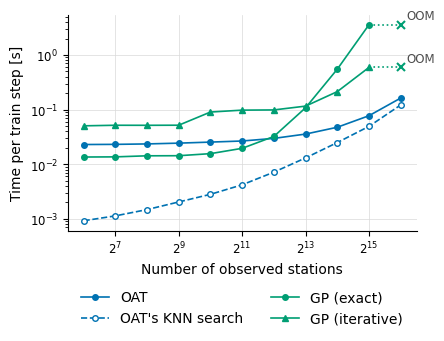

In [ ]:
# def plot_scaling(ax, experiment_path, label, color, step='train', column='mean_s'):
#     table = pd.read_csv(pathlib.Path(experiment_path) / 'results.csv')
#     rows = table[(table['step'] == step) & (table['status'] == 'ok')]
#     ax.plot(rows['n_obs'], rows[column], marker='o', ms=4, lw=1.2, color=color, label=label)


# def plot_scaling(ax, experiment_path, label, color, step='train', column='mean_s'):




with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(4.5, 2.8))

    # step = 'inference'
    step = 'train'
    column = 'mean_s'
    plot_scaling(ax, oat_fixed_results_path, label='OAT', color='#0072B2', step=step, column=column)
    # plot_scaling(ax, oat_fixed_results_path, label="OAT's KNN", color="#909090", step='knn', column=column)
    plot_scaling(ax, oat_fixed_results_path, label="OAT's KNN search", color='#0072B2',
             step='knn', column=column, linestyle='--', marker_face='white')
    # plot_scaling(ax, gp_fixed_results_path, label='GP', color='#D55E00', step=step, column=column)
    # plot_scaling(ax, gp_fixed_exact_results_path, label='GP-Exact', color='#009E73', step=step, column=column)
    plot_scaling(ax, gp_fixed_exact_results_path, label='GP (exact)', color='#009E73', step=step, column=column)
    plot_scaling(ax, gp_fixed_results_path,       label='GP (iterative)',    color='#009E73', step=step, column=column, marker='^')

    # plot_scaling(ax, deep_gp_fixed_results_path, label='Deep GP', color='#56B4E9', step=step, column=column)

    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('Number of observed stations')
    ax.set_ylabel(f'Time per {step} step [s]')
    ax.grid(True, which='major', lw=0.5, color='0.85')
    # ax.legend(frameon=False)
    ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.22))

    # ax.set_title(f'{"Training" if step == "train" else "Inference"} with 1024 query points.')
    
    # plt.show()
    display(fig)    # show exactly this figure
    
    name = f'station_scaling_fixed_{step}'
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{name}.pdf', bbox_inches='tight')
    
    plt.close(fig)

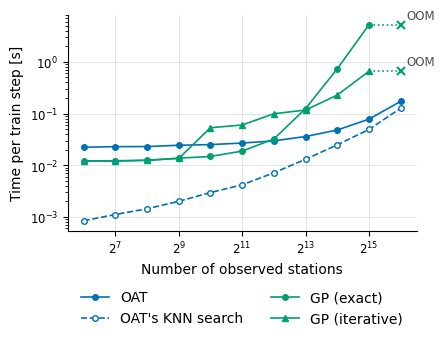

In [6]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(4.5, 2.8))

    # step = 'inference'
    step = 'train'
    column = 'mean_s'
    plot_scaling(ax, oat_proportional_results_path, label='OAT', color='#0072B2', step=step, column=column)

    plot_scaling(ax, oat_proportional_results_path, label="OAT's KNN search", color='#0072B2',
             step='knn', column=column, linestyle='--', marker_face='white')

    plot_scaling(ax, gp_proportional_exact_results_path, label='GP (exact)', color='#009E73', step=step, column=column)
    plot_scaling(ax, gp_proportional_results_path,       label='GP (iterative)',    color='#009E73', step=step, column=column, marker='^')


    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('Number of observed stations')
    ax.set_ylabel(f'Time per {step} step [s]')
    ax.grid(True, which='major', lw=0.5, color='0.85')
    # ax.legend(frameon=False)
    ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.22))

    # ax.set_title(f'{"Training" if step == "train" else "Inference"} with proportional query points.')
    
    # plt.show()
    display(fig)    # show exactly this figure
    
    name = f'station_scaling_proportional_{step}'
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{name}.pdf', bbox_inches='tight')
    
    plt.close(fig)

In [4]:
oat_fixed_fullattention_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-08_00-33-15_oat_full_attention_fixed_B1'
oat_proportional_fullattention_results_path = '/users/miccatta/s-ruc/observation_assimilation_transformer/benchmarking/scaling_benchmark/2026-10-08_00-34-01_oat_full_attention_proportional_B1'

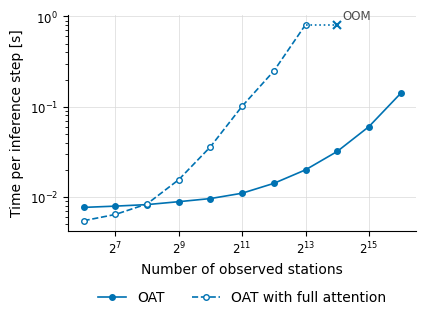

In [15]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(4.5, 2.8))

    step = 'inference'
    # step = 'train'
    column = 'mean_s'
    plot_scaling(ax, oat_fixed_results_path, label='OAT', color='#0072B2', step=step, column=column)
    # plot_scaling(ax, oat_proportional_results_path, label='OAT', color='#0072B2', step=step, column=column)
    # plot_scaling(ax, gp_fixed_exact_results_path, label='GP (exact)', color='#009E73', step=step, column=column)
    plot_scaling(ax, oat_fixed_fullattention_results_path, label='OAT with full attention', color='#0072B2', step=step, column=column, linestyle='--', marker_face='white')
    # plot_scaling(ax, oat_proportional_fullattention_results_path, label='OAT with full attention', color='#0072B2', step=step, column=column, linestyle='--', marker_face='white')


    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('Number of observed stations')
    ax.set_ylabel(f'Time per {step} step [s]')
    ax.grid(True, which='major', lw=0.5, color='0.85')
    # ax.legend(frameon=False)
    ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.22))

    # ax.set_title(f'{"Training" if step == "train" else "Inference"} with proportional query points.')
    
    # plt.show()
    display(fig)    # show exactly this figure
    
    name = f'fullattention_vs_sparse_fixed_{step}'
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{name}.pdf', bbox_inches='tight')
    
    plt.close(fig)

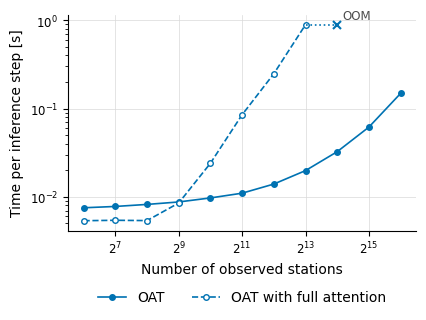

In [18]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(4.5, 2.8))

    step = 'inference'
    # step = 'train'
    column = 'mean_s'
    # plot_scaling(ax, oat_fixed_results_path, label='OAT', color='#0072B2', step=step, column=column)
    plot_scaling(ax, oat_proportional_results_path, label='OAT', color='#0072B2', step=step, column=column)
    # plot_scaling(ax, gp_fixed_exact_results_path, label='GP (exact)', color='#009E73', step=step, column=column)
    # plot_scaling(ax, oat_fixed_fullattention_results_path, label='OAT with full attention', color='#0072B2', step=step, column=column, linestyle='--', marker_face='white')
    plot_scaling(ax, oat_proportional_fullattention_results_path, label='OAT with full attention', color='#0072B2', step=step, column=column, linestyle='--', marker_face='white')


    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('Number of observed stations')
    ax.set_ylabel(f'Time per {step} step [s]')
    ax.grid(True, which='major', lw=0.5, color='0.85')
    # ax.legend(frameon=False)
    ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.22))

    # ax.set_title(f'{"Training" if step == "train" else "Inference"} with proportional query points.')
    
    # plt.show()
    display(fig)    # show exactly this figure
    
    name = f'fullattention_vs_sparse_proportional_{step}'
    fig.savefig(FIGURE_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{name}.pdf', bbox_inches='tight')
    
    
    plt.close(fig)